Данная лабораторная посвящена работе с текстовыми данными.

Для общего развития (или если возникнут проблемы при выполнении заданий) рекомендуется ознакомиться с материалами курса по NLP, в частности с блокнотами 2 и 4:

1. [Вводная часть](https://colab.research.google.com/drive/1Fc9mAY-d-uA_x0naBQHYjbOSD7JyS0bf)

2. [Предобработка текста](https://colab.research.google.com/drive/1Lk4GcoS8KlXqjPXX6vK1teYbzaV5hNV8)

3. [Анализ и визуализация текстовых данных](https://colab.research.google.com/drive/1LoDu-ZvC4cKnfQTcgq_4Ya5gKmDyKg96)

4. [Векторизация](https://colab.research.google.com/drive/1n71YET2VbYIwyY0jYC5G1Zlkgl5ZInJ9)

5. [Другие задачи в области NLP](https://colab.research.google.com/drive/1u5IjpGisDXd_XH96lKTadJ8rKsg3VXD5)

Если вкратце, то компьютер умеет работать только с числами, а текст - это не числа, поэтому основная задача NLP - эффективно превратить текст в набор чисел (векторизовать). В идеале мы стремимся к тому, чтобы сохранить смысловую составляющую.

Важный факт, на который вы можете опираться при выполнении заданий:

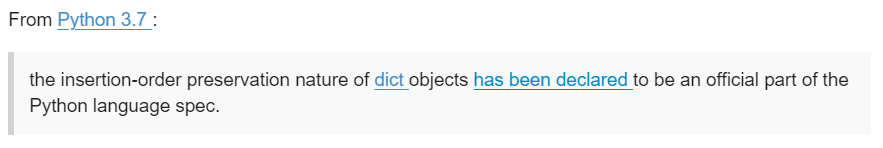

**Баллы (максимум 14):**

| Раздел | Баллы |
|---|---|
| Данные | 3 |
| Bag of Words | 3 |
| Keywords (BoW) | 0.5 |
| TF-IDF | 3 |
| Keywords (TF-IDF) | 0.5 |
| Вопрос: NB vs LinearSVC | 0.5 |
| GloVe | 3 |
| Самый главный вопрос | 0.5 |

**Что сдать:** ноутбук, выполненный сверху вниз без ошибок (Restart & Run All), собранный датасет (`.csv`) или код для его воспроизведения, ответы во всех ячейках **Ответ**, итоговая таблица в конце.

**Критерии проверки:**

* нет утечки данных — векторайзеры и `GridSearchCV` обучаются только на train;
* собственные `BagOfWords` и `TFIDF` совпадают с эталонными выводами и сопоставимы по качеству с sklearn;
* тесты в разделе GloVe проходят;
* для каждого эксперимента есть метрики и время, выводы сформулированы словами.

Выводы под ячейками в шаблоне — эталонные результаты, сверяйтесь с ними.

# Анализ текстовых данных

## Данные (3 балла)

Задача, которую мы будем пытаться решить, представляет собой классификацию коротких текстов по доменным областям знания, которым они принадлежат. Доменных областей (domain) будет 4. Данные возьмем с [OpenAlex](https://docs.openalex.org/).

Соберите не менее 10k англоязычных записей с OpenAlex. Для каждой записи сохраните поля `id`, `title`, `abstract`, `domain`. Сохраняйте только те записи, у которых присутствуют все необходимые поля. Вероятно, вам пригодится [эта страница](https://docs.openalex.org/how-to-use-the-api/get-lists-of-entities/paging) документации.

**Подсказки:**

* используйте cursor paging (`cursor=*`, затем `meta.next_cursor`), `per-page=200`, фильтр `language:en`;
* `abstract` в API отдаётся как `abstract_inverted_index` (слово → список позиций) — восстановите из него текст;
* `domain` берётся из `primary_topic.domain.display_name`;
* делайте `sleep` между запросами и сохраните датасет в CSV, чтобы не скачивать его повторно.

In [31]:
import os
import requests
from time import sleep
import pandas as pd


DATA_PATH = 'openalex_works.csv'
N_RECORDS = 10_000


def restore_abstract(inverted_index):
    """abstract_inverted_index (слово -> позиции) -> обычный текст."""
    if not inverted_index:
        return None
    positions = [(pos, word) for word, poses in inverted_index.items() for pos in poses]
    return ' '.join(word for _, word in sorted(positions))


def parse_work(work):
    topic = work.get('primary_topic') or {}
    domain = (topic.get('domain') or {}).get('display_name')
    return {
        'id': work.get('id'),
        'title': work.get('title'),
        'abstract': restore_abstract(work.get('abstract_inverted_index')),
        'domain': domain,
    }


def fetch_openalex(n_records=N_RECORDS, per_page=200, pause=0.2):
    url = 'https://api.openalex.org/works'
    params = {
        'filter': 'language:en,has_abstract:true',
        'sort': 'cited_by_count:desc',
        'select': 'id,title,abstract_inverted_index,primary_topic',
        'per-page': per_page,
        'cursor': '*',
    }
    records = []
    while len(records) < n_records and params['cursor']:
        response = requests.get(url, params=params, timeout=60)
        response.raise_for_status()
        data = response.json()
        for work in data['results']:
            rec = parse_work(work)
            if all(rec.values()):  # сохраняем только записи со всеми полями
                records.append(rec)
        params['cursor'] = data['meta'].get('next_cursor')
        sleep(pause)
    return pd.DataFrame(records).drop_duplicates('id').head(n_records).reset_index(drop=True)


if os.path.exists(DATA_PATH):
    df = pd.read_csv(DATA_PATH)
else:
    df = fetch_openalex()
    df.to_csv(DATA_PATH, index=False)

df.head()

,id,title,abstract,domain
0,https://openalex.org/W3038568908,Radiation Resistant Camera System for Monitori...,Radiation resistant camera system was construc...,Physical Sciences
1,https://openalex.org/W2582743722,R: A Language and Environment for Statistical ...,This introduction to R is derived from an orig...,Physical Sciences
2,https://openalex.org/W1775749144,PROTEIN MEASUREMENT WITH THE FOLIN PHENOL REAGENT,Since 1922 when Wu proposed the use of the Fol...,Life Sciences
3,https://openalex.org/W2194775991,Deep Residual Learning for Image Recognition,Deeper neural networks are more difficult to t...,Physical Sciences
4,https://openalex.org/W1981368803,Generalized Gradient Approximation Made Simple,Generalized gradient approximations (GGA's) fo...,Physical Sciences


Изучите собранные данные. Минимально выведите следующую информацию:

* общее количество записей;

* количество уникальных значений (какие и сколько) для доменных областей;

* распределение количества символов и количества слов для `title` и `abstract`.

Есть ли дисбаланс классов? Как он может повлиять на выбор метрики?

**Ответ:** да, классы несбалансированы: Physical Sciences ≈ 42%, Social Sciences ≈ 28%, Life и Health Sciences примерно по 15%. Поэтому accuracy будет завышаться за счёт крупного класса, и основной метрикой берём **macro-F1**: она усредняет F1 по классам с равными весами, так что малые классы тоже учитываются. По той же причине разбиение делаем со `stratify=y`.

Всего записей: 10000

Домены:
domain
Physical Sciences    4164
Social Sciences      2849
Life Sciences        1500
Health Sciences      1487
Name: count, dtype: int64
domain
Physical Sciences    0.416
Social Sciences      0.285
Life Sciences        0.150
Health Sciences      0.149
Name: proportion, dtype: float64


,title_chars,title_words,abstract_chars,abstract_words
count,10000.0,10000.0,10000.0,10000.0
mean,65.4,8.7,1185.3,173.1
std,32.6,4.5,1328.8,214.0
min,3.0,1.0,1.0,1.0
25%,42.0,6.0,651.0,95.0
50%,61.0,8.0,992.0,145.0
75%,83.0,11.0,1469.2,211.0
max,323.0,52.0,29889.0,5132.0


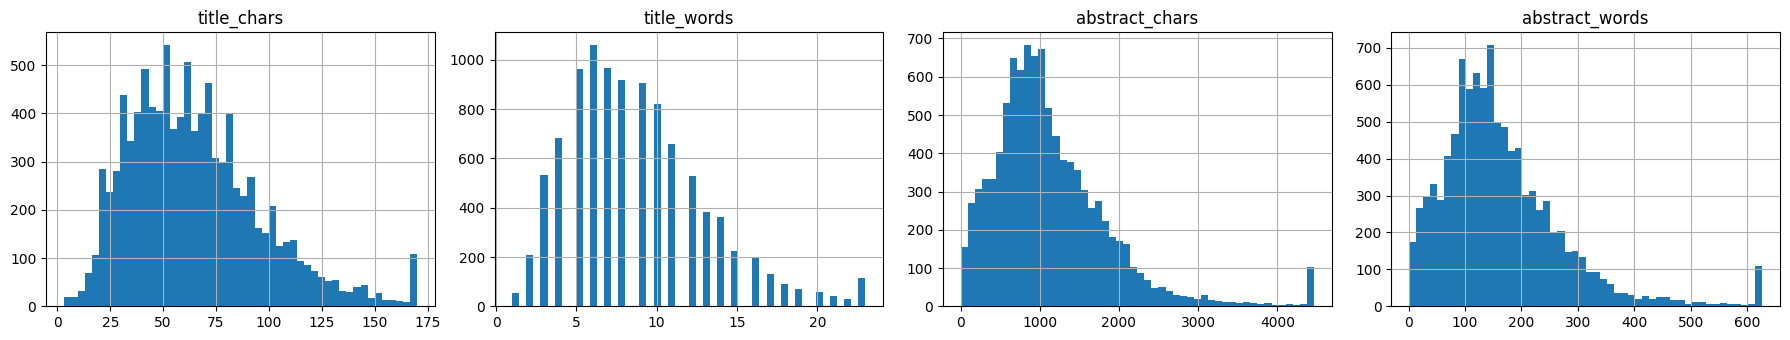

In [32]:
import matplotlib.pyplot as plt

print('Всего записей:', len(df))
print('\nДомены:')
print(df['domain'].value_counts())
print(df['domain'].value_counts(normalize=True).round(3))

for col in ['title', 'abstract']:
    df[f'{col}_chars'] = df[col].str.len()
    df[f'{col}_words'] = df[col].str.split().str.len()

stats_cols = ['title_chars', 'title_words', 'abstract_chars', 'abstract_words']
display(df[stats_cols].describe().round(1))

fig, axes = plt.subplots(1, 4, figsize=(18, 3.5))
for ax, col in zip(axes, stats_cols):
    df[col].clip(upper=df[col].quantile(0.99)).hist(bins=50, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

df = df.drop(columns=stats_cols)

Напишите функцию для предобработки текстовых данных. Она должна включать следующие шаги:

1. приведение текста к нижнему регистру;

2. удаление пунктуации и чисел;

3. лемматизация;

4. удаление стоп-слов;

5. удаление лишних пробельных символов.

Объедините `title` и `abstract` в один текст. Проведите его предобработку.

Для лемматизации подойдёт `nltk` (`WordNetLemmatizer`) или `spacy`. Для `nltk` понадобятся `nltk.download('punkt_tab')`, `'wordnet'`, `'stopwords'`.

Результат сохраните в колонку `title_abstract_preprocessed` — она используется в разделе GloVe.

In [2]:
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize

for pkg in ['punkt_tab', 'wordnet', 'stopwords']:
    nltk.download(pkg, quiet=True)

STOP_WORDS = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()


def preprocess(text):
    text = text.lower()                                     # 1. нижний регистр
    text = re.sub(r'[^a-z\s]', ' ', text)                   # 2. пунктуация и числа
    # 3. лемматизация; стоп-слова фильтруем до неё, иначе WordNet превращает 'was' -> 'wa', 'has' -> 'ha'
    lemmas = (lemmatizer.lemmatize(w) for w in text.split() if w not in STOP_WORDS)
    words = [w for w in lemmas if w not in STOP_WORDS and len(w) > 1]  # 4. стоп-слова (после лемматизации)
    return ' '.join(words)                                  # 5. лишние пробелы (split/join)


df['title_abstract'] = df['title'] + '\n' + df['abstract']
df['title_abstract_preprocessed'] = df['title_abstract'].apply(preprocess)

df.head()

NameError: name 'df' is not defined

В качестве алгоритма классификации будем использовать Наивный Байес (`MultinomialNB`) и `LinearSVC` с фиксированным `random_state`=42.

Для оценки разделите ваши данные в соотношении 80:20. Сделайте это ДО проведения любой векторизации. Общее правило, чтобы понять, можно применять обработку до разделения или только после - если ваша предобработка работает с каждой записью независимо, то можно применить её до разделения. Иначе, если при обработке одной записи используется какая-либо информация из других записей (среднее, уникальные значения, общее кол-во и так далее), применять её рекомендуется только после разделения.

При оценке используйте `classification_report` и `confusion_matrix` (для визуализации пригодится `seaborn.heatmap`).

Разбиение: `train_test_split(..., test_size=0.2, random_state=42, stratify=y)`.

Оформите обучение и оценку в одну функцию (fit → predict → время → `classification_report` → heatmap) и переиспользуйте её во всех разделах. Результаты (векторайзер, классификатор, macro-F1, время) складывайте в общий список — он понадобится в итоговой таблице.

In [34]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC


clf1 = MultinomialNB()
clf2 = LinearSVC(random_state=42)

In [35]:
import time
import warnings
from sklearn.exceptions import ConvergenceWarning
from sklearn.pipeline import Pipeline
import seaborn as sns
from sklearn.base import clone
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from sklearn.model_selection import train_test_split

X = df['title_abstract_preprocessed']
y = df['domain']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print('train:', X_train.shape, 'test:', X_test.shape)

warnings.filterwarnings('ignore', category=ConvergenceWarning)  # LinearSVC на сырых счётчиках

LABELS = sorted(y.unique())
results = []  # (векторайзер, классификатор, macro-F1, время) для итоговой таблицы


def evaluate(clf, X_tr, y_tr, X_te, y_te, vectorizer_name, vec_time=0.0, plot=True):
    """fit -> predict -> время -> classification_report -> heatmap. Результат пишется в results."""
    clf = clone(clf)
    start = time.perf_counter()
    clf.fit(X_tr, y_tr)
    fit_time = time.perf_counter() - start
    y_pred = clf.predict(X_te)

    macro_f1 = f1_score(y_te, y_pred, average='macro')
    clf_name = type(clf[-1] if isinstance(clf, Pipeline) else clf).__name__
    total_time = vec_time + fit_time
    print(f'=== {vectorizer_name} + {clf_name}: macro-F1 = {macro_f1:.4f}, '
          f'векторизация {vec_time:.2f} c, обучение {fit_time:.2f} c')
    if plot:
        print(classification_report(y_te, y_pred, digits=3))
        cm = confusion_matrix(y_te, y_pred, labels=LABELS)
        plt.figure(figsize=(5, 4))
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=LABELS, yticklabels=LABELS)
        plt.title(f'{vectorizer_name} + {clf_name}')
        plt.xlabel('predicted')
        plt.ylabel('true')
        plt.show()
    results.append({'vectorizer': vectorizer_name, 'classifier': clf_name,
                    'macro_f1': round(macro_f1, 4), 'time_s': round(total_time, 2)})
    return macro_f1

train: (8000,) test: (2000,)


## Bag of Words (3 балла)

"Мешок слов" (Bag of Words, BoW) — это самый простой подход к векторизации текста.

Порядок слов не учитывается, а вся информация об анализируемом тексте сосредоточена в частоте встречаемости слов.
```
docs = [
  {'word1': 2, 'word2': 0, 'word3': 8, ...},
  {'word1': 1, 'word2': 0, 'word3': 2, ...},
  ...
  ]

len(docs[i].keys()) = общее кол-во слов ('word1', 'word2', 'word3', ...) в корпусе
docs[i] - представление i-того документа
```

Основные шаги алгоритма:

1. токенизация;

2. fit: построение словаря: создание словаря из всех уникальных слов, встречающихся в корпусе;

3. transform: подсчет частоты: для каждого слова из словаря подсчитывается, сколько раз оно встречается в тексте.

Допишите класс со следующей сигнатурой (можно добавить ещё методы). Работать будем только со словами. Параметр max_features отвечает за фиксированную длину вектора (подумайте, как длина вектора связана с объемом словаря).

Требования:

* поддержка n-грамм из `ngram_range`;
* токенизация — `nltk.word_tokenize`, регистр не меняется (`"word's"` → `["word", "'s"]`, `"tf-idf"` остаётся одним токеном);
* ключи словаря — n-граммы в виде кортежей: `('word',)`, `('BoW', 'transforms')`;
* порядок словаря и отбор `max_features` — `Counter.most_common` по суммарной частоте в корпусе; при равной частоте порядок первого появления (в каждом документе сначала все униграммы, затем биграммы);
* результат на тестовых предложениях ниже должен совпасть с эталонным выводом.

In [36]:
from collections import Counter
import numpy as np
from nltk.tokenize import word_tokenize


class BagOfWords:
    """
    Bag of Words модель для векторизации текстовых данных.

    Параметры:
        ngram_range (tuple): Диапазон n-грамм для создания признаков.
        max_features (int): Максимальное количество признаков для использования.

    Атрибуты:
        ngram_range (tuple): Диапазон n-грамм для создания признаков.
        max_features (int): Максимальное количество признаков для использования.
        vocabulary (dict): Словарь, сопоставляющий токены частоте их встречаемости.
    """

    def __init__(self, ngram_range=(1, 1), max_features=None):
        self.ngram_range = ngram_range
        self.max_features = max_features
        self.vocabulary = {}

    def fit(self, documents):
        """
        Создает словарь на основе предоставленных документов.

        Параметры:
            documents (list): Список текстовых документов.
        """
        counter = Counter()  # порядок вставки = порядок первого появления
        for doc in documents:
            counter.update(self.ngrams(doc))
        # most_common сортирует стабильно: при равной частоте сохраняется порядок первого появления
        self.vocabulary = dict(counter.most_common(self.max_features))
        self.index = {ngram: i for i, ngram in enumerate(self.vocabulary)}
        return self

    def transform(self, documents):
        """
        Преобразует текстовые документы в векторное представление с использованием созданного словаря.

        Параметры:
            documents (list): Список текстовых документов.

        Возвращает:
            list: Векторное представление документов.
        """
        if not len(self.vocabulary):
            raise ValueError("The vocabulary has not been created. Call fit method first.")
        vectors = np.zeros((len(documents), len(self.vocabulary)), dtype=np.int32)
        for row, doc in enumerate(documents):
            for ngram in self.ngrams(doc):
                col = self.index.get(ngram)
                if col is not None:
                    vectors[row, col] += 1
        return vectors

    def fit_transform(self, documents):
        """
        Обучает модель на предоставленных документах и возвращает их векторное представление.

        Параметры:
            documents (list): Список текстовых документов.

        Возвращает:
            list: Векторное представление документов.
        """
        self.fit(documents)
        return self.transform(documents)

    def tokenize(self, text):
        """
        Разбивает текст на токены.

        Параметры:
            text (str): Текст для токенизации.

        Возвращает:
            list: Список токенов.
        """
        return word_tokenize(text)

    def ngrams(self, text):
        """Все n-граммы документа: сначала униграммы, затем биграммы и т.д."""
        tokens = self.tokenize(text)
        low, high = self.ngram_range
        return [tuple(tokens[i:i + n])
                for n in range(low, high + 1)
                for i in range(len(tokens) - n + 1)]

In [37]:
bow = BagOfWords(ngram_range=(1, 2), max_features=15)

test_sentences = [
    "BoW transforms text into a frequency vector based on words occurrence",
    "in BoW each word's count creates a unique feature",
    "BoW ignores word order focusing on word occurrence frequency",
]

vectors = bow.fit_transform(test_sentences)
pd.DataFrame(vectors, columns=list(bow.vocabulary.keys()))

,"(BoW,)","(word,)","(a,)","(frequency,)","(on,)","(occurrence,)","(transforms,)","(text,)","(into,)","(vector,)","(based,)","(words,)","(BoW, transforms)","(transforms, text)","(text, into)"
0,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1
1,1,1,1,0,0,0,0,0,0,0,0,0,0,0,0
2,1,2,0,1,1,1,0,0,0,0,0,0,0,0,0


Векторизуйте тексты с помощью вашего алгоритма. Обучите классификатор и оцените скорость работы и качество классификации по доменным областям (domain). Поэкспериментируйте с гиперпараметрами вашего векторайзера.

Замерьте время векторизации и обучения (`time.perf_counter`).

=== BagOfWords(1, 1), max_features=1000 + MultinomialNB: macro-F1 = 0.7914, векторизация 5.53 c, обучение 0.08 c
=== BagOfWords(1, 1), max_features=1000 + LinearSVC: macro-F1 = 0.7555, векторизация 5.53 c, обучение 1.39 c
=== BagOfWords(1, 1), max_features=5000 + MultinomialNB: macro-F1 = 0.8308, векторизация 5.82 c, обучение 0.57 c
=== BagOfWords(1, 1), max_features=5000 + LinearSVC: macro-F1 = 0.8061, векторизация 5.82 c, обучение 4.25 c
=== BagOfWords(1, 2), max_features=2000 + MultinomialNB: macro-F1 = 0.8098, векторизация 6.27 c, обучение 0.18 c
=== BagOfWords(1, 2), max_features=2000 + LinearSVC: macro-F1 = 0.7634, векторизация 6.27 c, обучение 3.71 c
=== BagOfWords(1, 2), max_features=5000 + MultinomialNB: macro-F1 = 0.8239, векторизация 6.44 c, обучение 0.58 c
                   precision    recall  f1-score   support

  Health Sciences      0.841     0.781     0.810       297
    Life Sciences      0.701     0.783     0.740       300
Physical Sciences      0.923     0.824     

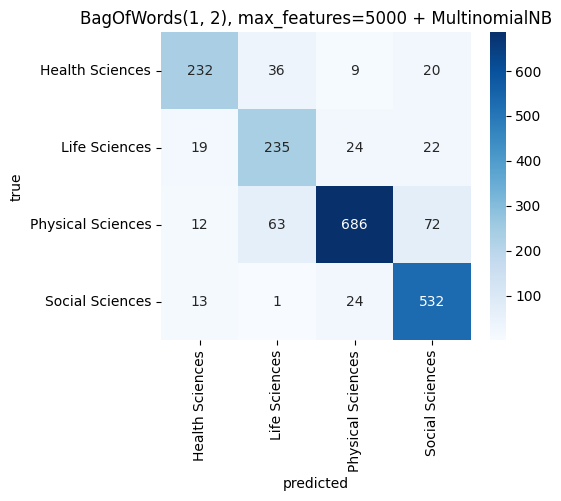

=== BagOfWords(1, 2), max_features=5000 + LinearSVC: macro-F1 = 0.8024, векторизация 6.44 c, обучение 4.29 c
                   precision    recall  f1-score   support

  Health Sciences      0.766     0.815     0.790       297
    Life Sciences      0.738     0.677     0.706       300
Physical Sciences      0.868     0.862     0.865       833
  Social Sciences      0.840     0.858     0.849       570

         accuracy                          0.826      2000
        macro avg      0.803     0.803     0.802      2000
     weighted avg      0.826     0.826     0.825      2000



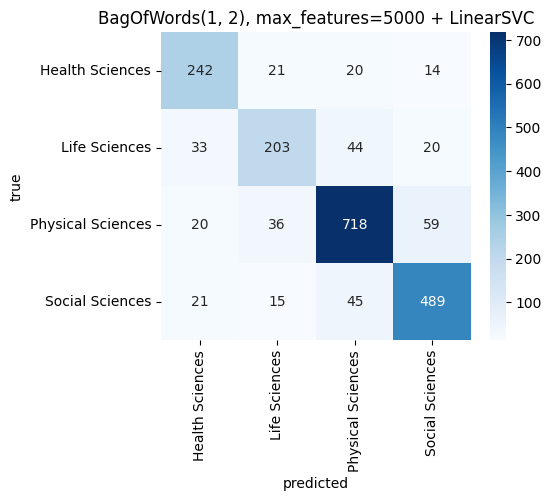

In [38]:
def run_custom(vectorizer_cls, ngram_range, max_features, plot=False):
    name = f'{vectorizer_cls.__name__}{ngram_range}, max_features={max_features}'
    vec = vectorizer_cls(ngram_range=ngram_range, max_features=max_features)
    start = time.perf_counter()
    Xtr = vec.fit_transform(list(X_train))  # словарь строится только на train
    Xte = vec.transform(list(X_test))
    vec_time = time.perf_counter() - start
    for clf in (clf1, clf2):
        evaluate(clf, Xtr, y_train, Xte, y_test, name, vec_time, plot=plot)


for ngram_range, max_features in [((1, 1), 1000), ((1, 1), 5000), ((1, 2), 2000)]:
    run_custom(BagOfWords, ngram_range, max_features)

run_custom(BagOfWords, (1, 2), 5000, plot=True)

Воспользуйтесь готовой реализацией CountVectorizer из sklearn. Сопоставимые ли результаты получаются? Подберите гиперпараметры с помощью GridSearch.

Используйте `Pipeline(vectorizer → classifier)`; `GridSearchCV` обучайте только на train.

**Ответ:** да, результаты сопоставимы. При одинаковых параметрах `(1, 2), max_features=5000` собственный `BagOfWords` даёт macro-F1 ≈ 0.824 (NB) / 0.806 (SVC), а `CountVectorizer` ≈ 0.824 / 0.803. Небольшая разница объясняется токенизацией: `CountVectorizer` по умолчанию отбрасывает токены из одного символа и иначе разрешает ничьи при отборе `max_features`. Зато sklearn работает примерно в 2 раза быстрее (≈2.8 c против ≈6 c) и возвращает разреженную матрицу, а наша реализация — плотную, которая занимает гораздо больше памяти.

GridSearch (3-fold CV только на train) показал, что сильнее всего помогает расширить словарь: NB лучше всего работает с `max_features=None, ngram_range=(1, 2), alpha=0.1` (macro-F1 на тесте ≈ 0.866), LinearSVC — с `max_features=20000, (1, 2), C=0.01` (≈ 0.849). На сырых счётчиках SVC нужна сильная регуляризация (маленький `C`), потому что признаки не нормированы.

=== CountVectorizer(1, 2), max_features=5000 + MultinomialNB: macro-F1 = 0.8235, векторизация 2.71 c, обучение 0.01 c
=== CountVectorizer(1, 2), max_features=5000 + LinearSVC: macro-F1 = 0.8006, векторизация 2.71 c, обучение 4.25 c
MultinomialNB: best CV macro-F1 = 0.8608 (14.3 c), best params = {'clf__alpha': 0.1, 'vec__max_features': None, 'vec__ngram_range': (1, 2)}
=== CountVectorizer GridSearch [alpha=0.1, max_features=None, ngram_range=(1, 2)] + MultinomialNB: macro-F1 = 0.8694, векторизация 0.00 c, обучение 2.30 c
                   precision    recall  f1-score   support

  Health Sciences      0.846     0.852     0.849       297
    Life Sciences      0.827     0.780     0.803       300
Physical Sciences      0.925     0.904     0.914       833
  Social Sciences      0.886     0.939     0.911       570

         accuracy                          0.887      2000
        macro avg      0.871     0.869     0.869      2000
     weighted avg      0.887     0.887     0.887      2000

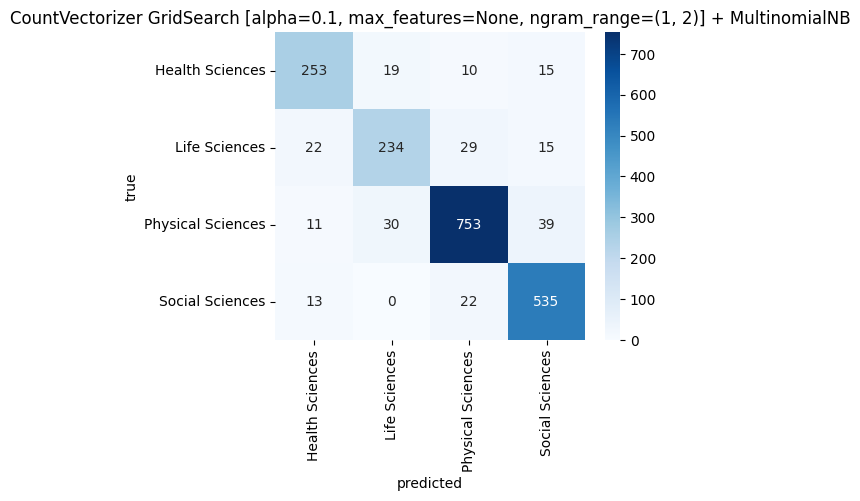

LinearSVC: best CV macro-F1 = 0.8480 (19.1 c), best params = {'clf__C': 0.01, 'vec__max_features': None, 'vec__ngram_range': (1, 2)}
=== CountVectorizer GridSearch [C=0.01, max_features=None, ngram_range=(1, 2)] + LinearSVC: macro-F1 = 0.8497, векторизация 0.00 c, обучение 2.80 c
                   precision    recall  f1-score   support

  Health Sciences      0.846     0.811     0.828       297
    Life Sciences      0.852     0.710     0.775       300
Physical Sciences      0.872     0.920     0.895       833
  Social Sciences      0.888     0.914     0.901       570

         accuracy                          0.871      2000
        macro avg      0.864     0.839     0.850      2000
     weighted avg      0.870     0.871     0.869      2000



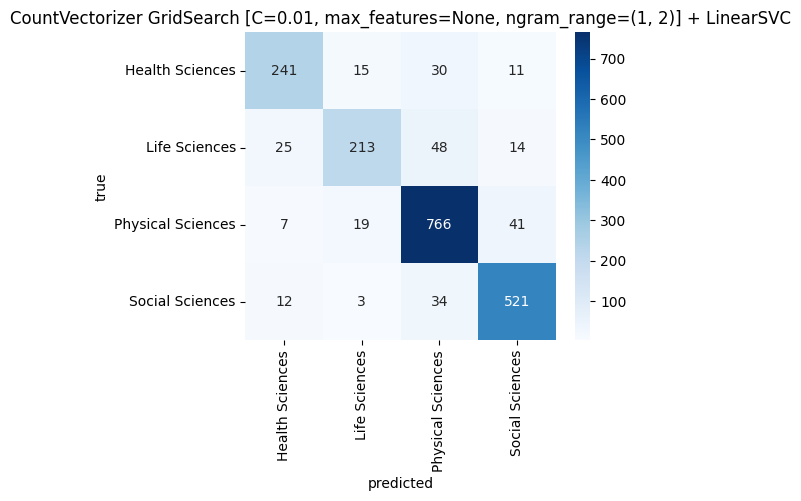

In [39]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.model_selection import GridSearchCV


def run_sklearn(vec, name, plot=False):
    start = time.perf_counter()
    Xtr = vec.fit_transform(X_train)
    Xte = vec.transform(X_test)
    vec_time = time.perf_counter() - start
    for clf in (clf1, clf2):
        evaluate(clf, Xtr, y_train, Xte, y_test, name, vec_time, plot=plot)


# те же параметры, что у собственной реализации, для прямого сравнения
run_sklearn(CountVectorizer(ngram_range=(1, 2), max_features=5000),
            'CountVectorizer(1, 2), max_features=5000')


def grid_search(vectorizer, vec_name, clf, clf_grid):
    pipe = Pipeline([('vec', vectorizer), ('clf', clf)])
    param_grid = {
        'vec__ngram_range': [(1, 1), (1, 2)],
        'vec__max_features': [5000, 20000, None],
        **clf_grid,
    }
    gs = GridSearchCV(pipe, param_grid, scoring='f1_macro', cv=3, n_jobs=-1)
    start = time.perf_counter()
    gs.fit(X_train, y_train)  # подбор только на train
    print(f'{type(clf).__name__}: best CV macro-F1 = {gs.best_score_:.4f} '
          f'({time.perf_counter() - start:.1f} c), best params = {gs.best_params_}')
    params = ', '.join(f'{k.split("__")[1]}={v}' for k, v in gs.best_params_.items())
    evaluate(gs.best_estimator_, X_train, y_train, X_test, y_test,
             f'{vec_name} GridSearch [{params}]', plot=True)
    return gs


gs_cv_nb = grid_search(CountVectorizer(), 'CountVectorizer', clf1, {'clf__alpha': [0.1, 0.5, 1.0]})
gs_cv_svc = grid_search(CountVectorizer(), 'CountVectorizer', clf2, {'clf__C': [0.01, 0.1, 1.0]})

### Keywords (0.5 балла)

Выведите топ-20 ключевых слов для каждого домена (то есть таких, которые превалируют именно в конкретном домене) и общие топ-20 слов по всем доменам. Используйте `CountVectorizer`.

Характерные для домена слова — не просто самые частые в нём (они будут общими для всех доменов), а те, чья доля в домене заметно выше, чем во всём корпусе.

In [40]:
def keywords_table(matrix, feature_names, domains, top_n=20, min_count=None):
    """
    Характерные слова домена: доля слова в домене / доля слова во всём корпусе (lift).
    Чтобы редкие слова не выигрывали за счёт случайности, берём только слова с весом >= min_count в домене.
    """
    total = np.asarray(matrix.sum(axis=0)).ravel()
    corpus_share = total / total.sum()
    table = {}
    for domain in sorted(domains.unique()):
        dom = np.asarray(matrix[(domains == domain).values].sum(axis=0)).ravel()
        lift = (dom / dom.sum()) / corpus_share
        if min_count is not None:
            lift[dom < min_count] = 0
        table[domain] = feature_names[np.argsort(-lift)[:top_n]]
    table['ALL (top by total)'] = feature_names[np.argsort(-total)[:top_n]]
    return pd.DataFrame(table)


count_vec = CountVectorizer(min_df=5)
counts = count_vec.fit_transform(df['title_abstract_preprocessed'])
bow_keywords = keywords_table(counts, count_vec.get_feature_names_out(), df['domain'], min_count=30)
bow_keywords

,Health Sciences,Life Sciences,Physical Sciences,Social Sciences,ALL (top by total)
0,aasld,pfam,voc,amos,data
1,atrial,mirbase,pseudopotentials,crime,method
2,ipilimumab,mirnas,vapor,democracy,model
3,hpv,mirna,supercapacitors,ptsd,analysis
4,rr,raxml,radiative,earnings,study
5,comorbidities,kegg,iot,ownership,research
6,nafld,seq,nanocrystals,trustworthiness,new
7,creatinine,histone,tio,entrepreneurship,patient
8,fibrillation,crispr,nanomaterials,aversion,system
9,hcc,kappab,microwave,strobe,theory


## TF-IDF (3 балла)

TF-IDF представляет собой числовую статистику, отражающую важность слова в документе относительно коллекции документов (корпуса). Мы всё еще считаем частоту слов, но теперь делаем это более по-умному.

Оценка TF-IDF вычисляется с использованием двух основных компонент: частоты термина (TF) и обратной частоты документа (IDF).

1. **TF**
   
   Измеряет, насколько часто термин (слово) встречается в документе. Рассчитывается как отношение числа раз, когда термин появляется в документе, к общему числу терминов в этом документе.
   
   $$ \text{TF}(t, d) = \frac{\text{Количество раз, когда термин } t \text{ появляется в документе } d}{\text{Общее количество терминов в документе } d} $$

2. **IDF**
   
   Измеряет важность термина по всему корпусу. Она рассчитывается как логарифм отношения общего числа документов к числу документов, содержащих термин, плюс единица для избежания деления на ноль.

   $$ \text{IDF}(t, D) = \log\left(\frac{\text{Общее количество документов в корпусе } N}{\text{Количество документов, содержащих термин } t + 1} \right) $$

   Здесь \(N\) - общее количество документов в корпусе.
   Логарифм нужен для сглаживания.

   **P.S.** В sklearn используется формула $$ \text{IDF}(t, D) = \log\left(\frac{\text{Общее количество документов в корпусе } N + 1}{\text{Количество документов, содержащих термин } t + 1} \right) + 1 $$

   В вашей реализации нужно будет использовать именно её.

   **Важно:** в этой лабораторной TF — просто количество вхождений термина в документ, без деления на длину документа и без L2-нормировки. Именно так получен эталонный вывод ниже.

3. **Оценка TF-IDF:**
   
   $$ \text{TF-IDF}(t, d, D) = \text{TF}(t, d) \times \text{IDF}(t, D) $$

   Эта оценка присваивает более высокий вес терминам, часто встречающимся в конкретном документе, но относительно редким в общей коллекции документов.

Ваша задача - реализовать класс со следующей сигнатурой (можно менять или добавлять методы при необходимости) для векторизации с помощью TF-IDF подхода. Используйте разбиение только по словам. При отборе `max_features` ориентируйтесь на term frequency.

Требования:

* IDF — по формуле sklearn (см. выше), TF — количество вхождений;
* токенизация — `nltk.word_tokenize`, регистр не меняется (`"word's"` → `["word", "'s"]`, `"tf-idf"` остаётся одним токеном);
* ключи словаря — n-граммы в виде кортежей: `('word',)`, `('BoW', 'transforms')`;
* порядок словаря и отбор `max_features` — `Counter.most_common` по суммарной частоте в корпусе; при равной частоте порядок первого появления (в каждом документе сначала все униграммы, затем биграммы);
* результат на тестовых предложениях ниже должен совпасть с эталонным выводом.

Чем ваша реализация отличается от `TfidfVectorizer` по умолчанию (подсказка: параметр `norm`)?

**Ответ:** `TfidfVectorizer` по умолчанию использует `norm='l2'`: после умножения tf·idf каждый вектор документа делится на свою евклидову норму, и все документы оказываются на единичной сфере. Поэтому длинный абстракт не получает больших значений признаков только за счёт длины. Наша реализация (как и эталон) нормировку не делает, она эквивалентна `TfidfVectorizer(norm=None)`. Ещё отличие: sklearn по умолчанию отбрасывает однобуквенные токены (`token_pattern`) и приводит текст к нижнему регистру.

In [41]:
class TFIDF(BagOfWords):
    """
    TF-IDF модель для векторизации текстовых данных.
    Токенизация, n-граммы и отбор max_features наследуются от BagOfWords.

    Параметры:
        ngram_range (tuple): Диапазон n-грамм для создания признаков.
        max_features (int): Максимальное количество признаков для использования.

    Атрибуты:
        ngram_range (tuple): Диапазон n-грамм для создания признаков.
        max_features (int): Максимальное количество признаков для использования.
        vocabulary (dict): Словарь, сопоставляющий n-граммы их idf.
    """

    def fit(self, documents):
        """
        Создает словарь на основе предоставленных документов.

        Параметры:
            documents (list): Список текстовых документов.
        """
        super().fit(documents)  # отбор max_features по term frequency
        doc_freq = Counter()
        for doc in documents:
            doc_freq.update(set(self.ngrams(doc)) & self.index.keys())
        n_docs = len(documents)
        # idf по формуле sklearn: ln((N + 1) / (df + 1)) + 1
        self.vocabulary = {ngram: np.log((n_docs + 1) / (doc_freq[ngram] + 1)) + 1
                           for ngram in self.vocabulary}
        self.idf = np.array(list(self.vocabulary.values()), dtype=np.float32)
        return self

    def transform(self, documents):
        """
        Преобразует текстовые документы в векторное представление с использованием созданного словаря.

        Параметры:
            documents (list): Список текстовых документов.

        Возвращает:
            list: Векторное представление документов.
        """
        tf = super().transform(documents)  # tf = число вхождений, без нормировки
        return tf * self.idf

In [42]:
tfidf = TFIDF(ngram_range=(1, 2), max_features=15)

test_sentences = [
    "tf-idf measures word importance relative to its frequency in a document",
    "tf-idf considers word uniqueness across all documents in the corpus",
    "it identifies significant words common in a document yet rare across all documents"
]

vectors = tfidf.fit_transform(test_sentences)
pd.DataFrame(vectors, columns=list(tfidf.vocabulary.keys()))

,"(in,)","(tf-idf,)","(word,)","(a,)","(document,)","(in, a)","(a, document)","(across,)","(all,)","(documents,)","(across, all)","(all, documents)","(measures,)","(importance,)","(relative,)"
0,1.0,1.287682,1.287682,1.287682,1.287682,1.287682,1.287682,0.000000,0.000000,0.000000,0.000000,0.000000,1.693147,1.693147,1.693147
1,1.0,1.287682,1.287682,0.000000,0.000000,0.000000,0.000000,1.287682,1.287682,1.287682,1.287682,1.287682,0.000000,0.000000,0.000000
2,1.0,0.000000,0.000000,1.287682,1.287682,1.287682,1.287682,1.287682,1.287682,1.287682,1.287682,1.287682,0.000000,0.000000,0.000000


Векторизуйте тексты с помощью вашего алгоритма. Обучите классификатор и оцените скорость работы и качество классификации по доменным областям (domain). Поэкспериментируйте с гиперпараметрами вашего векторайзера.

Замерьте время векторизации и обучения (`time.perf_counter`).

=== TFIDF(1, 1), max_features=1000 + MultinomialNB: macro-F1 = 0.7959, векторизация 8.10 c, обучение 0.02 c
=== TFIDF(1, 1), max_features=1000 + LinearSVC: macro-F1 = 0.7469, векторизация 8.10 c, обучение 3.09 c
=== TFIDF(1, 1), max_features=5000 + MultinomialNB: macro-F1 = 0.8352, векторизация 8.43 c, обучение 0.07 c
=== TFIDF(1, 1), max_features=5000 + LinearSVC: macro-F1 = 0.8076, векторизация 8.43 c, обучение 3.32 c
=== TFIDF(1, 2), max_features=2000 + MultinomialNB: macro-F1 = 0.8077, векторизация 8.93 c, обучение 0.04 c
=== TFIDF(1, 2), max_features=2000 + LinearSVC: macro-F1 = 0.7587, векторизация 8.93 c, обучение 3.24 c
=== TFIDF(1, 2), max_features=5000 + MultinomialNB: macro-F1 = 0.8277, векторизация 9.24 c, обучение 0.07 c
                   precision    recall  f1-score   support

  Health Sciences      0.845     0.791     0.817       297
    Life Sciences      0.708     0.793     0.748       300
Physical Sciences      0.925     0.818     0.868       833
  Social Sciences  

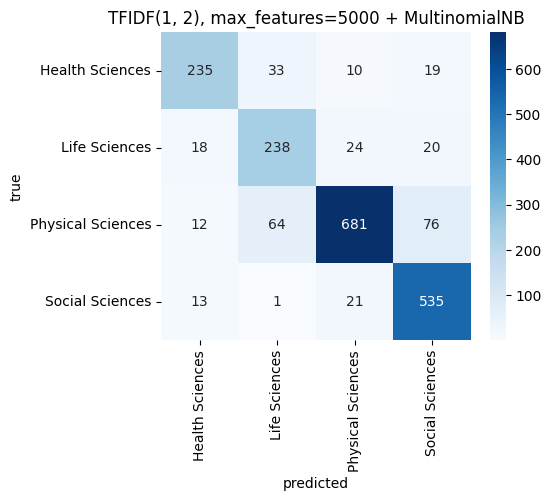

=== TFIDF(1, 2), max_features=5000 + LinearSVC: macro-F1 = 0.8037, векторизация 9.24 c, обучение 3.50 c
                   precision    recall  f1-score   support

  Health Sciences      0.768     0.801     0.784       297
    Life Sciences      0.741     0.687     0.713       300
Physical Sciences      0.870     0.864     0.867       833
  Social Sciences      0.841     0.861     0.851       570

         accuracy                          0.828      2000
        macro avg      0.805     0.803     0.804      2000
     weighted avg      0.827     0.828     0.827      2000



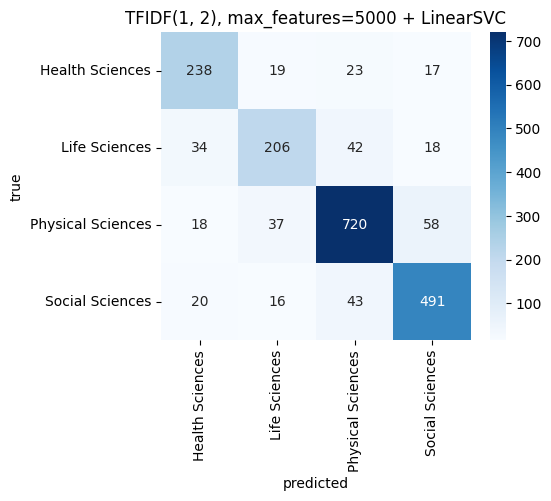

In [43]:
for ngram_range, max_features in [((1, 1), 1000), ((1, 1), 5000), ((1, 2), 2000)]:
    run_custom(TFIDF, ngram_range, max_features)

run_custom(TFIDF, (1, 2), 5000, plot=True)

Воспользуйтесь готовой реализацией TfIdfVectorizer из sklearn. Сопоставимые ли результаты получаются? Подберите гиперпараметры с помощью GridSearch.

Используйте `Pipeline`; `GridSearchCV` обучайте только на train.

**Ответ:** да. `TfidfVectorizer(norm=None)` с теми же параметрами практически совпадает с нашим `TFIDF` (macro-F1 ≈ 0.826 / 0.801 против 0.827 / 0.800). С L2-нормировкой (поведение по умолчанию) LinearSVC заметно улучшается (0.80 → 0.855) и обучается в десятки раз быстрее (≈0.1 c против ≈3.7 c), потому что нормированные признаки хорошо обусловлены и оптимизация сходится быстро. На NB нормировка почти не влияет. Лучшие параметры GridSearch: NB — `max_features=None, (1, 2), alpha=0.01` (≈ 0.869), LinearSVC — `max_features=20000, (1, 2), C=1.0` (≈ 0.872, лучший результат среди BoW/TF-IDF).

=== TfidfVectorizer(1, 2), max_features=5000, norm=None + MultinomialNB: macro-F1 = 0.8274, векторизация 2.78 c, обучение 0.01 c
=== TfidfVectorizer(1, 2), max_features=5000, norm=None + LinearSVC: macro-F1 = 0.8012, векторизация 2.78 c, обучение 3.51 c
=== TfidfVectorizer(1, 2), max_features=5000, norm=l2 + MultinomialNB: macro-F1 = 0.8209, векторизация 2.83 c, обучение 0.01 c
=== TfidfVectorizer(1, 2), max_features=5000, norm=l2 + LinearSVC: macro-F1 = 0.8503, векторизация 2.83 c, обучение 0.13 c
MultinomialNB: best CV macro-F1 = 0.8654 (17.7 c), best params = {'clf__alpha': 0.01, 'vec__max_features': None, 'vec__ngram_range': (1, 2), 'vec__sublinear_tf': False}
=== TfidfVectorizer GridSearch [alpha=0.01, max_features=None, ngram_range=(1, 2), sublinear_tf=False] + MultinomialNB: macro-F1 = 0.8683, векторизация 0.00 c, обучение 2.38 c
                   precision    recall  f1-score   support

  Health Sciences      0.839     0.875     0.857       297
    Life Sciences      0.839    

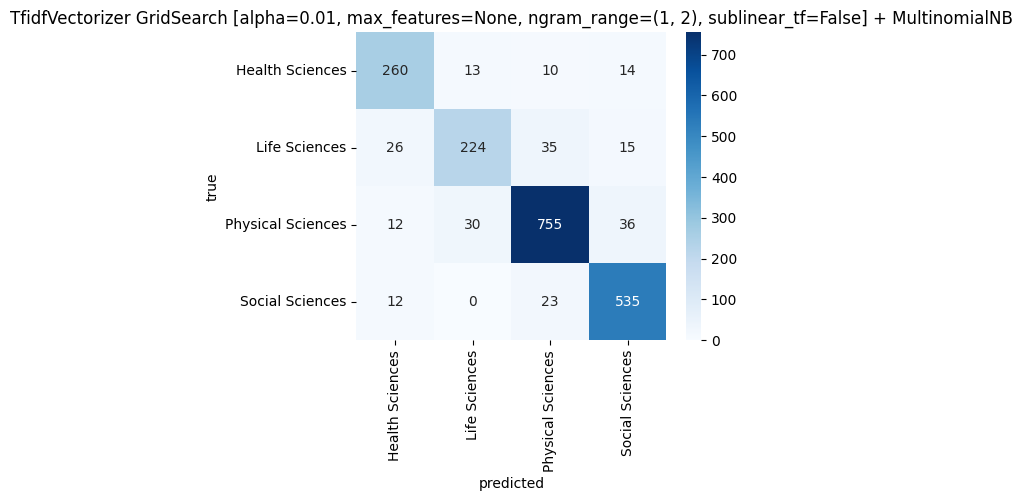

LinearSVC: best CV macro-F1 = 0.8661 (19.9 c), best params = {'clf__C': 1.0, 'vec__max_features': 20000, 'vec__ngram_range': (1, 2), 'vec__sublinear_tf': False}
=== TfidfVectorizer GridSearch [C=1.0, max_features=20000, ngram_range=(1, 2), sublinear_tf=False] + LinearSVC: macro-F1 = 0.8725, векторизация 0.00 c, обучение 2.88 c
                   precision    recall  f1-score   support

  Health Sciences      0.842     0.862     0.852       297
    Life Sciences      0.865     0.767     0.813       300
Physical Sciences      0.901     0.918     0.910       833
  Social Sciences      0.907     0.925     0.916       570

         accuracy                          0.889      2000
        macro avg      0.879     0.868     0.872      2000
     weighted avg      0.889     0.889     0.888      2000



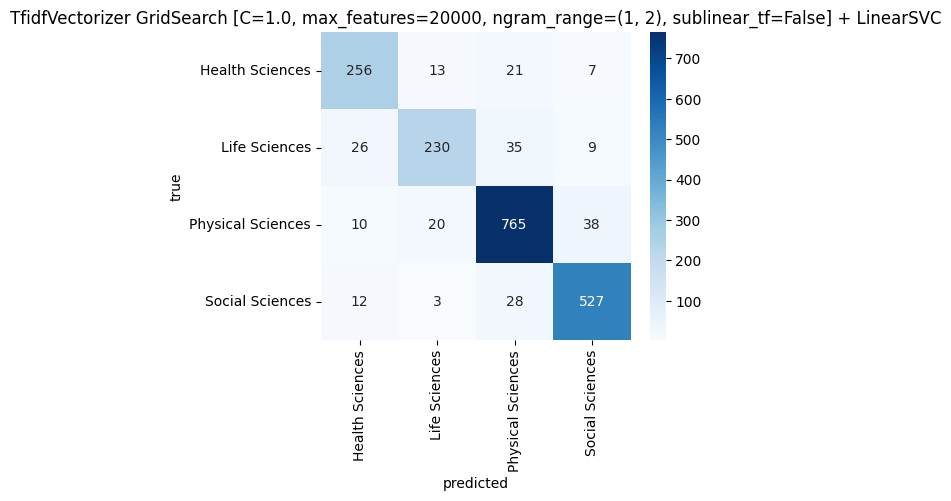

In [44]:
from sklearn.feature_extraction.text import TfidfVectorizer

# прямое сравнение с собственной реализацией: norm=None — тот же расчёт, что в TFIDF
run_sklearn(TfidfVectorizer(ngram_range=(1, 2), max_features=5000, norm=None),
            'TfidfVectorizer(1, 2), max_features=5000, norm=None')
# по умолчанию norm='l2'
run_sklearn(TfidfVectorizer(ngram_range=(1, 2), max_features=5000),
            'TfidfVectorizer(1, 2), max_features=5000, norm=l2')

tfidf_grid = {'vec__sublinear_tf': [False, True]}
gs_tfidf_nb = grid_search(TfidfVectorizer(), 'TfidfVectorizer', clf1,
                          {**tfidf_grid, 'clf__alpha': [0.01, 0.1, 1.0]})
gs_tfidf_svc = grid_search(TfidfVectorizer(), 'TfidfVectorizer', clf2,
                           {**tfidf_grid, 'clf__C': [0.1, 0.5, 1.0]})

### Keywords (0.5 балла)

Выведите топ-20 ключевых слов для каждого домена (то есть таких, которые превалируют именно в конкретном домене) и общие топ-20 слов по всем доменам. Используйте TF-IDF. Есть ли отличия по сравнению с тем, что получалось при использовании мешка слов?

**Ответ:** ключевые слова по доменам в основном те же (`mirna`, `crispr`, `kegg` — Life; `nivolumab`, `icu`, `gastric` — Health; `pseudopotentials`, `hartree`, `iot` — Physical; `foucault`, `democracy`, `entrepreneurship` — Social), но TF-IDF сильнее поднимает «тематические» термины (`autophagy`, `perovskite`, `superconductivity`, `postmodernism`) и опускает служебные артефакты разметки (`mathrm`, `ifmmode`). В общем топ-20 разница заметнее: у BoW наверху просто частотные слова (`data`, `method`, `study`, `used`, `using`, `also`), а TF-IDF за счёт IDF штрафует слова, встречающиеся почти везде (`also`, `used`, `using` уходят), и выдвигает содержательные слова (`social`, `cell`, `network`, `information`).

In [45]:
tfidf_vec = TfidfVectorizer(min_df=5)
tfidf_matrix = tfidf_vec.fit_transform(df['title_abstract_preprocessed'])
# тот же lift, но по сумме весов TF-IDF; порог по весу вместо порога по частоте
tfidf_keywords = keywords_table(tfidf_matrix, tfidf_vec.get_feature_names_out(), df['domain'], min_count=3)
tfidf_keywords

,Health Sciences,Life Sciences,Physical Sciences,Social Sciences,ALL (top by total)
0,icu,pfam,crystallographic,modernity,model
1,creatinine,mirnas,collision,aversion,data
2,atrial,mirna,spl,liquidity,method
3,gemcitabine,seq,metallic,managerial,analysis
4,hpv,kegg,lstm,ownership,theory
5,fibrillation,crispr,semiconducting,democracy,research
6,neurologic,haplotype,decoder,foucault,system
7,hcc,mega,crust,freud,study
8,aortic,ncbi,pseudopotentials,entrepreneurship,new
9,autophagy,uniprot,plasmon,postmodernism,social


### Вопрос (0.5 балла)

С каким векторайзером (и какими его гиперпараметрами) лучше работает Наивный Байес? А с каким `LinearSVC`? Предположите, чем обусловлена разница в качестве. Ответьте письменно.

**Ответ:**

* **Наивный Байес** лучше всего работает со **счётчиками или ненормированным TF-IDF и большим словарём** (`max_features=None`, униграммы + биграммы, маленькое сглаживание `alpha=0.01–0.1`): macro-F1 ≈ 0.866–0.869. L2-нормировка ему почти ничего не даёт.
* **LinearSVC** лучше всего работает с **TF-IDF + L2-нормировкой** (`TfidfVectorizer`, `(1, 2)`, `max_features=20000`, `C=1`): macro-F1 ≈ 0.872, лучший результат. На сырых счётчиках он заметно хуже (≈0.80) и требует сильной регуляризации (`C=0.01`).

**Почему так.** `MultinomialNB` — генеративная модель: она оценивает распределение частот слов в каждом классе, P(слово | класс), и предполагает, что признаки — это (псевдо)счётчики. Масштаб документа ей не мешает, а новые редкие признаки (биграммы, полный словарь) почти бесплатно добавляют сигнал, потому что каждый признак оценивается независимо. LinearSVC — дискриминативная модель с отступом (margin): она чувствительна к масштабу признаков. Без нормировки длинные абстракты имеют огромные значения признаков, оптимизация плохо сходится, и модель переобучается на длину документа. L2-нормировка и IDF-взвешивание выравнивают масштаб, и SVM может использовать свою сильную сторону — находить оптимальную разделяющую гиперплоскость в высокоразмерном разреженном пространстве.

## [GloVe](https://nlp.stanford.edu/projects/glove/) (3 балла)

GloVe (Global Vectors) — это метод векторного представления слов, предназначенный для извлечения семантической информации из текста. Он позволяет представлять слова в виде векторов в многомерном пространстве, где схожие слова расположены близко друг к другу.

GloVe стремится захватить семантические отношения между словами на основе их частоты встречаемости в корпусе текста. Основная идея заключается в том, чтобы определить, насколько часто два слова встречаются вместе.

Сначала строится матрица совстречаемости, в которой каждый элемент отражает, насколько часто слово $i$ встречается в контексте слова $j$. Затем делается матричное разложение, чтобы получить более компактные эмбеддинги.

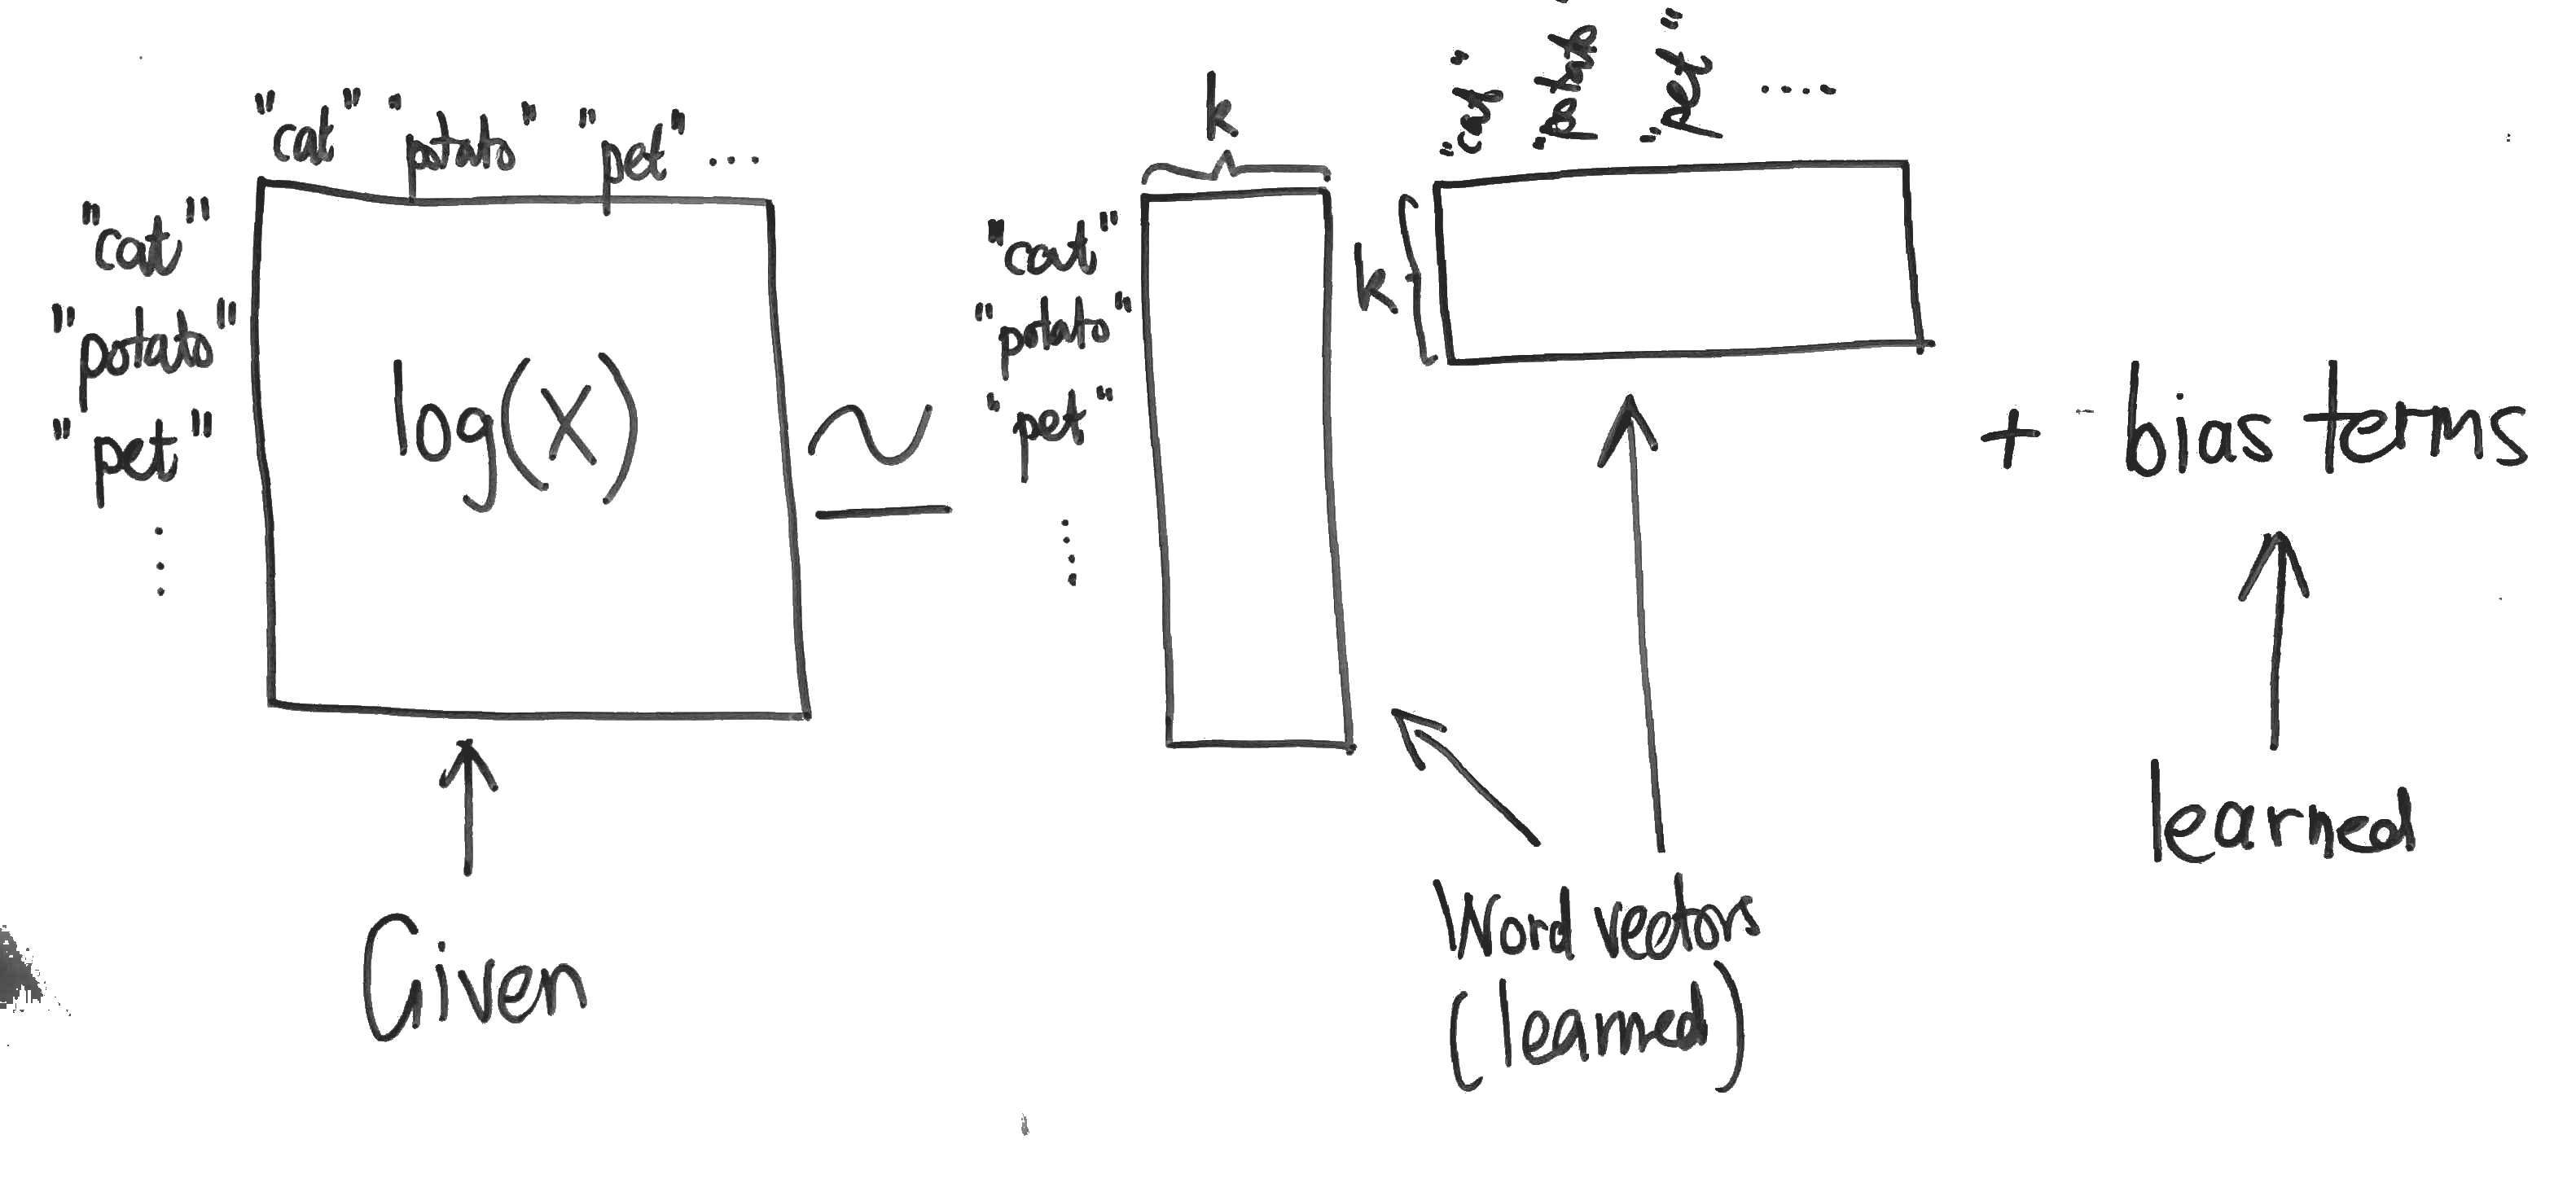

Чтобы реализовать всю эту красоту, потребуется алгоритм для матричной факторизации, а именно сингулярное разложение. Очень хорошее объяснение можно найти [по ссылке](https://davetang.org/file/Singular_Value_Decomposition_Tutorial.pdf).

При работе с большими матрицами будет проблематично высчитать все собственные значения, поэтому как всегда в подобных случаях воспользуемся градиентным спуском. Функция потерь MSE.

Допишите реализацию.

In [46]:
import numpy as np


def svd_gradient_descent(A, k, learning_rate=0.001, epochs=100):
    """
    Параметры:
    A (numpy.ndarray): Входная матрица (m, n).
    k (int): Количество сингулярных значений для вычисления.
    learning_rate (float): Скорость обучения для градиентного спуска.
    epochs (int): Количество итераций для градиентного спуска.

    Возвращает:
    U (numpy.ndarray): Левые сингулярные векторы (m, k).
    V_T (numpy.ndarray): Правые сингулярные векторы (k, n).
    """

    m, n = A.shape
    np.random.seed(42)
    U = np.random.randn(m, k)
    V_T = np.random.randn(k, n)

    for _ in range(epochs):
        error = U @ V_T - A          # loss = 1/2 * ||U V_T - A||^2
        grad_U = error @ V_T.T       # dL/dU
        grad_V_T = U.T @ error       # dL/dV_T
        U -= learning_rate * grad_U
        V_T -= learning_rate * grad_V_T

    return U, V_T

In [47]:
# Примеры - значения матрицы Result должны приближаться к значениям исходной матрицам

print('-' * 50)

A = np.array([[3, 1, 1],
              [-1, 3, 1]])

U, V_T = svd_gradient_descent(A, k=2, learning_rate=0.1)
print("U:\n", U)
print("V_T:\n", V_T)
print("Result:\n", U @ V_T)

print('-' * 50)

A2 = np.array([[1, 2, 3],
               [4, 5, 6],
               [7, 8, 9]])

U2, V_T2 = svd_gradient_descent(A2, k=2, learning_rate=0.02, epochs=1000)
print("U2:\n", U2)
print("V_T2:\n", V_T2)
print("Result2:\n", U2 @ V_T2)

print('-' * 50)

--------------------------------------------------
U:
 [[ 1.53805671 -0.0920823 ]
 [ 0.13866564  1.91027916]]
V_T:
 [[ 1.91086831  0.74097264  0.67856272]
 [-0.66219211  1.51666449  0.47422737]]
Result:
 [[ 3.  1.  1.]
 [-1.  3.  1.]]
--------------------------------------------------
U2:
 [[0.65090812 1.40427696]
 [1.97364485 0.73170393]
 [3.29645905 0.05860432]]
V_T2:
 [[ 2.12838454  2.42148212  2.71457971]
 [-0.27439828  0.30182252  0.87804332]]
Result2:
 [[1.00005159 2.00000478 2.99995798]
 [3.99989688 4.99999044 6.00008401]
 [7.00005155 8.00000478 8.999958  ]]
--------------------------------------------------


Теперь реализуем сам алгоритм GloVe. Будем хранить матрицу со-встречаемости слов как разреженную матрицу (иначе не хватит оперативной памяти), а в качестве алгоритма для матричного разложения воспользуемся более оптимизированной, чем наша, версией "из коробки".

Сам код оформим в виде набора функций. Допишите реализацию.

In [48]:
import numpy as np
from collections import Counter
from sklearn.decomposition import TruncatedSVD
from scipy.sparse import csr_matrix


def get_distinct_words(corpus):
    """
    Извлекает уникальные слова из текстов корпуса.

    Параметры:
        corpus (list): Список списков, где каждый внутренний список - токенизированный текст документа.

    Возвращает:
        tuple: Кортеж, содержащий:
            - list: Отсортированный список уникальных слов в корпусе.
            - int: Общее количество уникальных слов в корпусе.
    """
    words = sorted({word for doc in corpus for word in doc})
    return words, len(words)


def compute_cooccurrence_matrix(corpus, window_size=1):
    """
    Вычисляет матрицу со-встречаемости для корпуса.

    Параметры:
        corpus (list): Список списков, где каждый внутренний список - токенизированный текст документа.
        window_size (int): Размер окна контекста для вычисления со-встречаемости (окно = центральное слово +- window_size).

    Возвращает:
        tuple: Кортеж, содержащий:
            - csr_matrix: Матрица со-встречаемости, представленная как разреженная матрица.
            - dict: Словарь, сопоставляющий каждое слово его индексу в матрице.
    """
    words, n_words = get_distinct_words(corpus)
    word2ind = {word: i for i, word in enumerate(words)}
    pairs = Counter()
    for doc in corpus:
        ids = [word2ind[word] for word in doc]
        for i, center in enumerate(ids):
            for j in range(max(0, i - window_size), min(len(ids), i + window_size + 1)):
                if j != i:
                    pairs[center, ids[j]] += 1
    rows, cols = zip(*pairs) if pairs else ((), ())
    M = csr_matrix((list(pairs.values()), (rows, cols)), shape=(n_words, n_words), dtype=np.float64)
    return M, word2ind


def normalize(M):
    """
    Нормализует строки матрицы.

    Параметры:
        M (numpy.ndarray): Матрица, которую нужно нормализовать.

    Возвращает:
        numpy.ndarray: Нормализованная матрица.
    """
    M_lengths = np.linalg.norm(M, axis=1)
    M_normalized = M / (M_lengths[:, np.newaxis] + 0.000001)  # сглаживание
    return M_normalized

In [49]:
# Тесты

corpus = [["apple", "banana", "apple"], ["orange", "banana", "grape"]]
distinct_words, num_words = get_distinct_words(corpus)
assert distinct_words == ["apple", "banana", "grape", "orange"]
assert num_words == 4
print("get_distinct_words() works correctly!")

corpus = [["apple", "banana", "apple"], ["orange", "banana", "grape"]]
window_size = 1
M, word2ind = compute_cooccurrence_matrix(corpus, window_size)
expected_indices = {'apple': 0, 'banana': 1, 'grape': 2, 'orange': 3}
expected_matrix = [[0., 2., 0., 0.],
                    [2., 0., 1., 1.],
                    [0., 1., 0., 0.],
                    [0., 1., 0., 0.]]
assert word2ind == expected_indices
assert (M.toarray() == expected_matrix).all()
print("compute_cooccurrence_matrix() works correctly!")

get_distinct_words() works correctly!
compute_cooccurrence_matrix() works correctly!


У нас не слишком большое количество данных, тем не менее, модель чему-то выучивается. На всём массиве она обучается около 4 часов.

In [50]:
# Уже обученная модель, чтобы не тратить время
# Локально (не в Colab): качаем через gdown из Python в текущую папку, если файлов ещё нет
import os

for file_id, file_name in [('1_-TnMejLJI78022kF2xDJo-bQgsCApL0', 'cooccurrence_matrix.pickle'),
                           ('1WHkeWrbxerj8HvAcemUuL4YwFbsiwSCj', 'word2ind.pickle')]:
    if not os.path.exists(file_name):
        import gdown  # нужен только если файлов ещё нет
        gdown.download(id=file_id, output=file_name)
print(os.listdir('.'))

['cooccurrence_matrix.pickle', 'lab4.ipynb', 'openalex_works.csv', 'task.md', 'word2ind.pickle']


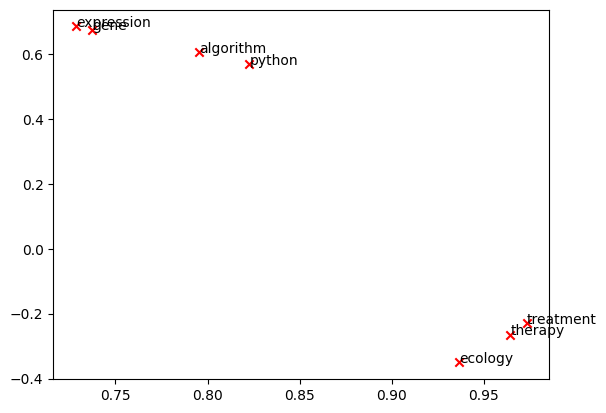

In [51]:
import pickle
import matplotlib.pyplot as plt


# corpus = df['title_abstract_preprocessed'].apply(lambda t: word_tokenize(t))
# M, word2ind = compute_cooccurrence_matrix(corpus, window_size=1)

with open("cooccurrence_matrix.pickle", "rb") as f:
    M = pickle.load(f)
with open("word2ind.pickle", "rb") as f:
    word2ind = pickle.load(f)

M_reduced =  TruncatedSVD(n_components=2).fit_transform(M)
embeddings = normalize(M_reduced)

for word in ['algorithm', 'ecology', 'expression', 'gene', 'python', 'treatment', 'therapy']:
    word_index = word2ind[word]
    word_embedding = embeddings[word_index]
    x, y = word_embedding[0], word_embedding[1]
    plt.scatter(x, y, marker='x', color='red')
    plt.text(x, y, word, fontsize=10);

In [52]:
len(word2ind)  # vocabulary size

82127

Для эмпирической оценки допишите функцию `most_similar`.

Само слово в выдачу не включайте.

In [53]:
from sklearn.metrics.pairwise import cosine_similarity


def most_similar(word, embeddings, word2ind, top_n=5):
    """
    Находит наиболее похожие на данное слово слова на основе косинусного сходства их векторных представлений.

    Параметры:
        word (str): Слово, для которого нужно найти похожие слова.
        embeddings (numpy.ndarray): Векторные представления слов.
        word2ind (dict): Словарь, сопоставляющий слова их индексам в матрице векторных представлений.
        top_n (int): Количество наиболее похожих слов для возврата.

    Возвращает:
        list: Список кортежей, содержащих наиболее похожие слова и их оценки косинусного сходства.
    """
    ind2word = {i: w for w, i in word2ind.items()}
    word_index = word2ind[word]
    similarities = cosine_similarity(embeddings[word_index:word_index + 1], embeddings)[0]
    nearest = [i for i in np.argsort(-similarities)[:top_n + 1] if i != word_index][:top_n]
    return [(ind2word[i], similarities[i]) for i in nearest]

In [54]:
M_reduced =  TruncatedSVD(n_components=312).fit_transform(M)
embeddings = normalize(M_reduced)

for word in ['algorithm', 'ecology', 'expression', 'gene', 'python', 'treatment']:
    print('-' * 50)
    print(word, end='\n\n')
    print(most_similar(word, embeddings, word2ind, top_n=10))

--------------------------------------------------
algorithm

[('method', np.float32(0.7988747)), ('approach', np.float32(0.78074646)), ('technique', np.float32(0.74874735)), ('procedure', np.float32(0.71506065)), ('scheme', np.float32(0.7042254)), ('heuristic', np.float32(0.6889997)), ('formulation', np.float32(0.6595877)), ('unsupervised', np.float32(0.6219591)), ('idea', np.float32(0.617024)), ('model', np.float32(0.61299735))]
--------------------------------------------------
ecology

[('industrial', np.float32(0.57672185)), ('diversity', np.float32(0.5640488)), ('environment', np.float32(0.56268877)), ('behaviour', np.float32(0.5532107)), ('resource', np.float32(0.5304259)), ('transformation', np.float32(0.5261229)), ('evolution', np.float32(0.5238789)), ('law', np.float32(0.522565)), ('ecological', np.float32(0.50932324)), ('theory', np.float32(0.507217))]
--------------------------------------------------
expression

[('proteincode', np.float32(0.9673891)), ('atrophydetermining

Теперь взглянем на реализацию "из коробки".

In [55]:
# !pip install gensim  # если gensim не установлен

def load_embedding_model():
    """ Load GloVe Vectors
        Return:
            wv_from_bin: All 400000 embeddings, each lengh 200
    """
    import gensim.downloader as api
    wv_from_bin = api.load("glove-wiki-gigaword-200")  # есть и другие модели, см. gensim.downloader.info()['models'].keys()
    print("Loaded vocab size %i" % len(list(wv_from_bin.index_to_key)))
    return wv_from_bin


wv_from_bin = load_embedding_model()

Loaded vocab size 400000


In [56]:
for word in ['algorithm', 'ecology', 'expression', 'gene', 'python', 'treatment']:
    print('-' * 50)
    print(word, end='\n\n')
    print(wv_from_bin.most_similar(word, 10))

--------------------------------------------------
algorithm

[('divide-and-conquer', 0.5534529089927673), ('krabat', 0.551224946975708), ('computes', 0.5506508946418762), ('jenalia.moreno@chron.com', 0.5458713173866272), ('fosterella', 0.5429463982582092), ('betterman', 0.540695071220398), ('starksia', 0.5393033623695374), ('algorithms', 0.5360755920410156), ('inugami', 0.5351618528366089), ('racinaea', 0.5292670130729675)]
--------------------------------------------------
ecology

[('icipe', 0.6646283864974976), ('zoogeography', 0.5999441742897034), ('ecofeminism', 0.5731804370880127), ('eco-systems', 0.546957790851593), ('energetics', 0.5300233364105225), ('palaeobiology', 0.5262896418571472), ('metapopulation', 0.5255571007728577), ('biogeochemistry', 0.5227234959602356), ('ecocriticism', 0.5164446234703064), ('afrofuturism', 0.5065551996231079)]
--------------------------------------------------
expression

[('sulf1', 0.6170405745506287), ('h19', 0.6167712211608887), ('dlc1', 0.6

Далее задания из серии "поиграться". Во всех заданиях необходимо пояснить результаты (1-2 предложения).

1. Выберите какое-либо многозначное слово. Найдите его ближайших соседей.

2. Найдите тройку слов $(w_1,w_2,w_3)$ таких, что $w_1$ и $w_2$ синонимы, а $w_1$ и $w_3$ антонимы, но косинусное расстояние между первым и третьим меньше, чем между первым и вторым.

3. Есть ли в векторах предвзятость? Попробуйте привести пример.

Используйте собственные слова, а не слова из примера ниже.

In [57]:
# Пример выполнения задания - в вашем ответе не используйте эти данные :)
from pprint import pprint

# 1
pprint(wv_from_bin.most_similar('head'))
print()

# 2
w1, w2, w3 = 'cat', 'feline', 'dog'
w1_w2_dist = wv_from_bin.distance(w1, w2)
w1_w3_dist = wv_from_bin.distance(w1, w3)
print("Synonyms {}, {} have cosine distance: {}".format(w1, w2, w1_w2_dist))
print("Antonyms {}, {} have cosine distance: {}".format(w1, w3, w1_w3_dist))
print()

# 3
A, B, C = 'mother', 'father', 'parent'
pprint(wv_from_bin.most_similar(positive=[A, C], negative=[B]))  # vector(mother) + vector(parent) - vector(father)
print('------------------------------------------------------')
pprint(wv_from_bin.most_similar(positive=[B, C], negative=[A]))  # vector(father) + vector(parent) - vector(mother)

[('heads', 0.7668997645378113),
 ('headed', 0.6344295144081116),
 ('chief', 0.6314131617546082),
 ('body', 0.6098024249076843),
 ('assistant', 0.6064105033874512),
 ('director', 0.6037707328796387),
 ('deputy', 0.5836146473884583),
 ('hand', 0.5738338232040405),
 ('left', 0.5574275255203247),
 ('arm', 0.5565925240516663)]

Synonyms cat, feline have cosine distance: 0.5149779319763184
Antonyms cat, dog have cosine distance: 0.2555125951766968

[('mothers', 0.5556671619415283),
 ('sister', 0.5390180945396423),
 ('pregnant', 0.5183460116386414),
 ('parents', 0.5059783458709717),
 ('mom', 0.4983614385128021),
 ('child', 0.47318556904792786),
 ('children', 0.47198641300201416),
 ('caregiver', 0.46677082777023315),
 ('girl', 0.46315866708755493),
 ('babies', 0.45548900961875916)]
------------------------------------------------------
[('company', 0.5688959360122681),
 ('subsidiary', 0.5497273802757263),
 ('ceo', 0.5028614401817322),
 ('owned', 0.5014129281044006),
 ('son', 0.4958716630935669

In [58]:
# 1. Многозначное слово
pprint(wv_from_bin.most_similar('mouse'))
print()

# 2. Синонимы vs антонимы
w1, w2, w3 = 'increase', 'raise', 'decrease'
print("Synonyms {}, {} have cosine distance: {}".format(w1, w2, wv_from_bin.distance(w1, w2)))
print("Antonyms {}, {} have cosine distance: {}".format(w1, w3, wv_from_bin.distance(w1, w3)))
print()

# 3. Предвзятость: programmer - man + woman и nurse - woman + man
pprint(wv_from_bin.most_similar(positive=['woman', 'programmer'], negative=['man'], topn=8))
print('------------------------------------------------------')
pprint(wv_from_bin.most_similar(positive=['man', 'programmer'], negative=['woman'], topn=8))
print('------------------------------------------------------')
pprint(wv_from_bin.most_similar(positive=['man', 'nurse'], negative=['woman'], topn=8))

[('mice', 0.6580958962440491),
 ('keyboard', 0.5548278093338013),
 ('rat', 0.5433949828147888),
 ('rabbit', 0.5192376971244812),
 ('cat', 0.5077415704727173),
 ('cursor', 0.5058691501617432),
 ('trackball', 0.5048902630805969),
 ('joystick', 0.49841049313545227),
 ('mickey', 0.47242844104766846),
 ('clicks', 0.4722806215286255)]

Synonyms increase, raise have cosine distance: 0.3012543320655823
Antonyms increase, decrease have cosine distance: 0.15036267042160034

[('programmers', 0.535283088684082),
 ('translator', 0.4743736684322357),
 ('freelance', 0.47011977434158325),
 ('educator', 0.4551157057285309),
 ('animator', 0.44057151675224304),
 ('aspiring', 0.43949082493782043),
 ('software', 0.4282291829586029),
 ('librarian', 0.4195935130119324)]
------------------------------------------------------
[('programmers', 0.5290838479995728),
 ('engineer', 0.48715341091156006),
 ('creator', 0.483517050743103),
 ('software', 0.4789707660675049),
 ('computer', 0.4682644307613373),
 ('animato

**Пояснения:**

1. **mouse** — среди соседей есть оба значения: животное (`mice`, `rat`, `rabbit`, `cat`) и устройство (`keyboard`, `cursor`, `trackball`, `joystick`). У слова один вектор, поэтому он оказывается «между» значениями и смешивает соседей из обоих контекстов.
2. **increase / raise / decrease**: антоним `decrease` ближе к `increase`, чем синоним `raise`. Антонимы встречаются в одинаковых контекстах («to increase/decrease the rate of …»), а GloVe учится как раз на совстречаемости, поэтому противоположные по смыслу слова получают близкие векторы.
3. **Предвзятость:** `programmer − man + woman` даёт `translator`, `educator`, `librarian`, а `programmer − woman + man` — `engineer`, `software`, `computer`. `nurse − woman + man` даёт `doctor`. Модель переняла гендерные стереотипы о профессиях из корпуса (Wikipedia + Gigaword).

Примените модель "из коробки" к вашим данным из OpenAlex так же, как в предыдущих заданиях. Оцените результаты. Вероятно, вам потребуется метод `get_mean_vector`.

Скорее всего, у вас не получится применить Наивный Байес. Почему?

Обучите `LinearSVC` на средних векторах документов и сравните качество с BoW и TF-IDF.

shape: (8000, 200) | min value: -0.189
=== GloVe-200 mean vector + LinearSVC: macro-F1 = 0.7990, векторизация 3.59 c, обучение 0.36 c
                   precision    recall  f1-score   support

  Health Sciences      0.788     0.811     0.799       297
    Life Sciences      0.805     0.577     0.672       300
Physical Sciences      0.843     0.885     0.864       833
  Social Sciences      0.836     0.888     0.861       570

         accuracy                          0.829      2000
        macro avg      0.818     0.790     0.799      2000
     weighted avg      0.827     0.829     0.825      2000



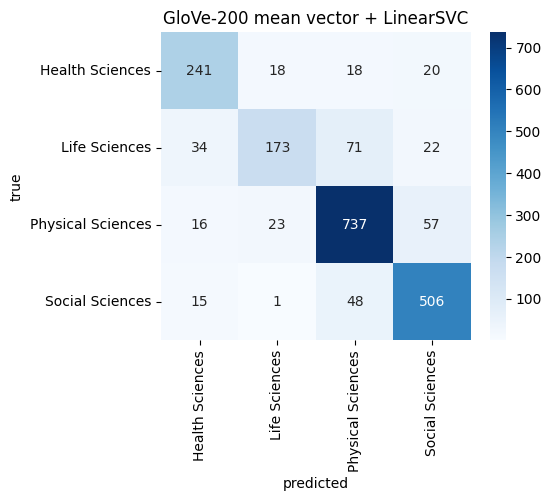

0.7989902820121805

In [59]:
def doc_vector(text, wv=wv_from_bin):
    """Документ = средний вектор слов, которые есть в словаре GloVe."""
    tokens = [w for w in text.split() if w in wv.key_to_index]
    return wv.get_mean_vector(tokens) if tokens else np.zeros(wv.vector_size, dtype=np.float32)


start = time.perf_counter()
X_train_glove = np.vstack(X_train.apply(doc_vector))
X_test_glove = np.vstack(X_test.apply(doc_vector))
glove_time = time.perf_counter() - start
print('shape:', X_train_glove.shape, '| min value:', X_train_glove.min().round(3))

evaluate(clf2, X_train_glove, y_train, X_test_glove, y_test,
         'GloVe-200 mean vector', glove_time, plot=True)

**Ответ** (почему не применим Наивный Байес): `MultinomialNB` моделирует признаки как неотрицательные счётчики (частоты слов) и оценивает по ним мультиномиальное распределение. Средний вектор GloVe — плотный вектор вещественных чисел, у которого компоненты бывают **отрицательными** (см. `min value` в выводе выше). На таких данных `MultinomialNB.fit` падает с ошибкой `Negative values in data passed to MultinomialNB`. Кроме того, отдельные координаты эмбеддинга — это не «количество чего-то», так что сама модель к ним неприменима по смыслу. Можно было бы взять `GaussianNB` или сдвинуть/масштабировать вектора, но это уже другая модель.

## Самый главный вопрос (0.5 балла)

Возможно, вы уже задавались вопросом, откуда именно появились доменные метки в данных, с которыми вы работали. Если нет - самое время задуматься. Разметить вручную несколько миллионов статей - задача, близкая к невозможной.

Изучите документацию OpenAlex. Письменно ответьте на вопрос, каким образом записи получают метки, а также какое влияние это потенциально имеет на ваш пайплайн классификации. Есть ли связь с так называемым явлением feedback loop?

Подсказки:

* как в OpenAlex проставляются topics/domains (автоматически или вручную, на основе каких данных);
* что на самом деле учит ваша модель, если метки сами получены моделью;
* что произойдёт, если такие предсказания снова попадут в данные для обучения.

**Ответ:**

**Как появляются метки.** Вручную их никто не ставит. В OpenAlex каждой работе автоматически присваиваются до трёх **topics** (≈4 500 тем) моделью-классификатором, которую OpenAlex разработал вместе с CWTS (Leiden). Модель использует **название, абстракт, название журнала/источника и цитирования** (что цитирует работа и кто цитирует её). Темы организованы в иерархию **topic → subfield → field → domain** (по образцу ASJC/Scopus): 4 домена — Life, Health, Physical, Social Sciences. `primary_topic` — тема с наибольшим score, и `domain` мы берём именно от неё. Для работ без абстракта модель опирается только на название и цитирования, и качество разметки ниже.

**Как это влияет на наш пайплайн.**
* Мы учим модель **воспроизводить предсказания другой модели**, а не «истинную» предметную область. Наши метрики показывают, насколько мы похожи на классификатор OpenAlex, и их потолок ограничен его ошибками: если OpenAlex ошибся, «правильный» ответ нашей модели засчитается как ошибка, и наоборот.
* Ошибки разметки систематические, а не случайные: междисциплинарные статьи (биоинформатика, медицинская физика, ML в биологии) попадают в один домен по одному признаку, например по журналу. Это видно в матрицах ошибок: больше всего путаются Life и Health Sciences, а также Physical и Life.
* У модели OpenAlex было больше информации (цитирования, журнал), чем у нас (только текст), так что часть меток в принципе нельзя восстановить по тексту.

**Связь с feedback loop.** Если предсказания моделей (OpenAlex или нашей) снова попадают в обучающие данные — например, OpenAlex дообучается на собственных метках, или мы размечаем новые статьи нашей моделью и добавляем их в train, — ошибки и смещения начинают **самоусиливаться**. Модель всё увереннее воспроизводит свои же ошибки, редкие и междисциплинарные темы «стягиваются» к крупным доменам (а у нас и так дисбаланс в пользу Physical Sciences), разнообразие разметки падает. Кроме того, исследователи и поисковые системы используют эти метки для поиска и рекомендаций, что влияет на то, кто какие статьи читает и цитирует. Цитирования — это вход модели, так что петля замыкается и в реальном мире. Чтобы такую петлю разорвать, нужна независимая «золотая» разметка экспертами хотя бы для валидационной выборки.

## Итоги

Соберите сравнительную таблицу всех экспериментов: векторайзер (с гиперпараметрами) × классификатор → macro-F1, время. Сделайте вывод, какой подход лучший и почему.

In [60]:
summary = (pd.DataFrame(results)
           .sort_values('macro_f1', ascending=False)
           .reset_index(drop=True))
pd.set_option('display.max_colwidth', 120)
summary

,vectorizer,classifier,macro_f1,time_s
0,"TfidfVectorizer GridSearch [C=1.0, max_features=20000, ngram_range=(1, 2), sublinear_tf=False]",LinearSVC,0.8725,2.88
1,"CountVectorizer GridSearch [alpha=0.1, max_features=None, ngram_range=(1, 2)]",MultinomialNB,0.8694,2.30
2,"TfidfVectorizer GridSearch [alpha=0.01, max_features=None, ngram_range=(1, 2), sublinear_tf=False]",MultinomialNB,0.8683,2.38
3,"TfidfVectorizer(1, 2), max_features=5000, norm=l2",LinearSVC,0.8503,2.96
4,"CountVectorizer GridSearch [C=0.01, max_features=None, ngram_range=(1, 2)]",LinearSVC,0.8497,2.80
5,"TFIDF(1, 1), max_features=5000",MultinomialNB,0.8352,8.51
6,"BagOfWords(1, 1), max_features=5000",MultinomialNB,0.8308,6.40
7,"TFIDF(1, 2), max_features=5000",MultinomialNB,0.8277,9.31
8,"TfidfVectorizer(1, 2), max_features=5000, norm=None",MultinomialNB,0.8274,2.79
9,"BagOfWords(1, 2), max_features=5000",MultinomialNB,0.8239,7.03


**Вывод:**

* **Лучший подход — `TfidfVectorizer` (L2-норма, униграммы + биграммы, ~20k признаков) + `LinearSVC`**: macro-F1 ≈ 0.87, обучение за несколько секунд. Почти так же хорош `MultinomialNB` на полном словаре (CountVectorizer или TF-IDF, `alpha` 0.01–0.1): ≈ 0.866–0.869. Он обучается быстрее всех и почти не требует настройки, поэтому это отличный baseline.
* Подбор гиперпараметров дал больше, чем выбор векторайзера: увеличение словаря с 1–5k до 20k+ признаков и добавление биграмм подняли macro-F1 с ≈0.80–0.83 до ≈0.85–0.87. Для SVM критична нормировка признаков.
* Собственные `BagOfWords`/`TFIDF` дают то же качество, что sklearn с теми же параметрами, но работают в 2–3 раза медленнее и хранят плотные матрицы. Для реальных задач нужны разреженные реализации sklearn.
* **Средние вектора GloVe** уступают разреженным представлениям (см. таблицу). Усреднение теряет специфичную терминологию (названия генов, лекарств, методов), которая и разделяет домены, а общий словарь Wikipedia/Gigaword плохо покрывает научную лексику. Зато признаков всего 200 — модель компактная и быстрая.
* Во всех моделях сложнее всего различить **Life и Health Sciences** (биомедицинская лексика пересекается). Кроме того, сами метки получены моделью OpenAlex (см. «Самый главный вопрос»), поэтому macro-F1 ≈ 0.87 — это скорее согласие с чужим классификатором, чем «истинная» точность.